# US real GNP growth: autoregressive dynamics and forecasting

Analyse the quarterly growth rate of **US real Gross National Product (GNP)**.
Compare AR(1) selected by BIC with AR(3) selected by AIC, interpret persistence
and oscillations, and produce next-quarter forecasts.
The main sample is **1947Q2-2019Q4 (291 quarters)**, before the pandemic.
A short final comparison extends estimation through 2025Q4.

Data Sources:

- BEA [NIPA Table 1.7.6](https://apps.bea.gov/national/Release/XLS/Survey/Section1All_xls.xlsx):
  quarterly US real GNP; the equivalent series is
  [GNPC96 on FRED](https://fred.stlouisfed.org/series/GNPC96).

GNP covers production attributable to US residents, domestically and abroad,
whereas GDP covers production within the country's borders.
All data are included locally; no download or API key is needed.

The values were retrieved on 14 October 2026. The forecast from 2019Q4 is a
historical teaching exercise using revised data, rather than a real-time forecast.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorize Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display

## Data

In [3]:
# Load quarterly real GNP levels and use a quarterly PeriodIndex.
# Values are in billions of chained 2017 dollars at an annual rate.
levels = pd.read_csv(DATA_DIR / "quarterly_real_gnp.csv", index_col="quarter")
levels.index = pd.PeriodIndex(levels.index, freq="Q")
if (list(levels.columns) != ["real_gnp"]
        or levels.isna().any().any()
        or not levels["real_gnp"].gt(0).all()):
    raise ValueError("Inspect the GNP column, missing observations and positive levels.")
# Check that quarters are consecutive; do not interpolate missing values.
if not levels.index.equals(pd.period_range(levels.index[0], levels.index[-1], freq="Q")):
    raise ValueError("Missing, duplicate or unordered quarters: inspect the CSV.")
display(levels.head())

,real_gnp
quarter,
1947Q1,2196.821
1947Q2,2191.585
1947Q3,2187.057
1947Q4,2221.790
1948Q1,2256.235


## Quarterly GNP growth

Calculate quarterly log growth from positive real GNP levels:

$$g_t=100[\log(Y_t)-\log(Y_{t-1})].$$

Growth approximates the percentage change **from one quarter to the next**,
without annualisation. The levels are in billions of chained 2017 dollars at
a seasonally adjusted annual rate; their constant scaling cancels in the ratio.
1947Q1 supplies the first growth base. Use all quarters through 2019Q4 for
the main analysis. Later values supply the held-out outcome and final comparison.
Differencing removes the level trend but does not by itself establish stationarity.

In [4]:
# Calculate log growth without annualising; remove only the base quarter.
all_growth = (100 * np.log(levels["real_gnp"]).diff()).iloc[1:].rename("Growth")
# Reserve later quarters for the held-out outcome and final comparison.
growth = all_growth.loc[:"2019Q4"].copy()
main_levels = levels.loc[:"2019Q4", "real_gnp"]
print(f"Main growth sample: {growth.index[0]} to {growth.index[-1]}, {len(growth)} quarters")
display(pd.DataFrame({"Real GNP": main_levels, "Growth (%)": growth}).loc[growth.index].head().round(3))

Main growth sample: 1947Q2 to 2019Q4, 291 quarters


,Real GNP,Growth (%)
quarter,,
1947Q2,2191.585,-0.239
1947Q3,2187.057,-0.207
1947Q4,2221.790,1.576
1948Q1,2256.235,1.538
1948Q2,2294.013,1.661


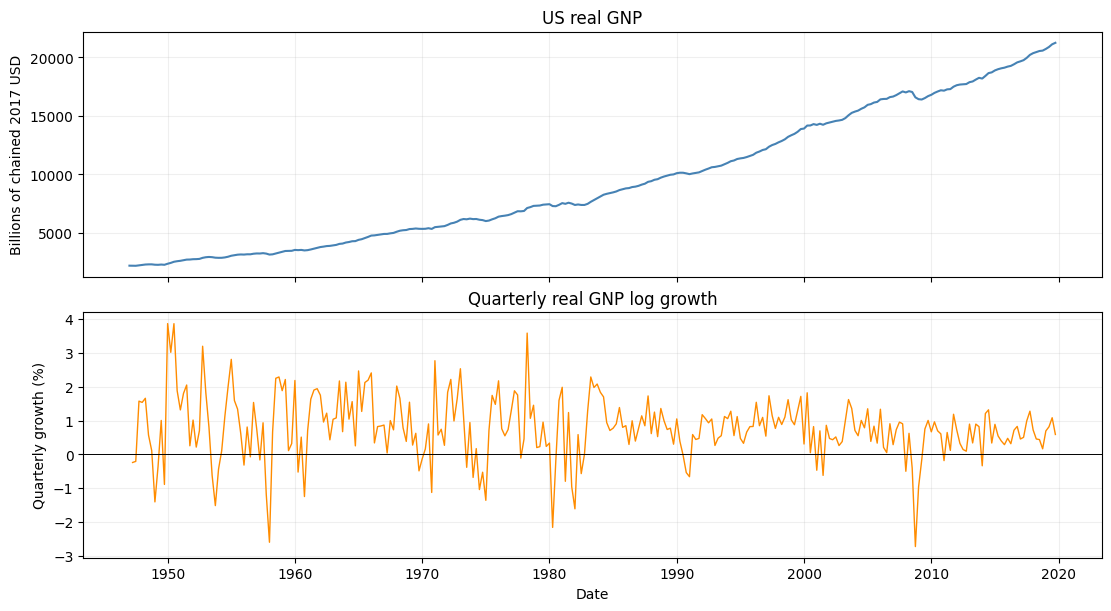

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
axes[0].plot(main_levels.index.to_timestamp(), main_levels, color="steelblue")
axes[0].set(title="US real GNP", ylabel="Billions of chained 2017 USD")
axes[1].plot(growth.index.to_timestamp(), growth, color="darkorange", linewidth=1)
axes[1].set(title="Quarterly real GNP log growth", ylabel="Quarterly growth (%)", xlabel="Date")
axes[1].axhline(0, color="black", linewidth=0.7)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

## ACF and PACF

The ACF measures correlation between growth and its lagged values. The PACF
measures that association after controlling for intermediate lags. For a
stationary population AR($p$), the PACF cuts off after lag $p$, while the ACF
usually decays. Sample plots are noisy, so use them as guides to lag selection.
Each lag is one quarter; the shaded 95% bands are approximate and pointwise.

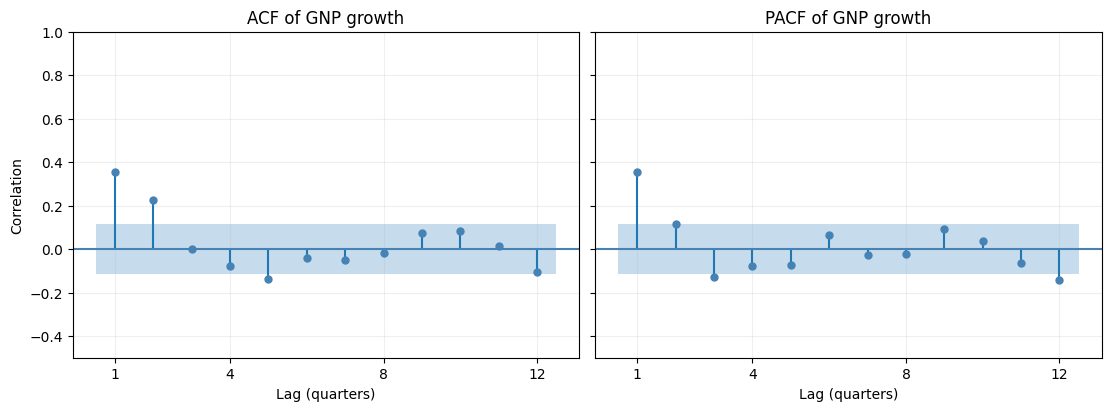

In [6]:
# One lag is one quarter. Omit lag zero and use pointwise 95% bands.
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, constrained_layout=True)
plot_acf(growth, lags=12, zero=False, bartlett_confint=False, ax=axes[0], color="steelblue")
plot_pacf(growth, lags=12, zero=False, method="ywm", ax=axes[1], color="steelblue")
for ax, title in zip(axes, ["ACF of GNP growth", "PACF of GNP growth"]):
    ax.set(title=title, xlabel="Lag (quarters)", ylim=(-0.5, 1))
    ax.set_xticks([1, 4, 8, 12])
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Correlation")
plt.show()

## The AR model and lag selection

Estimate an autoregression with an intercept:

$$g_t=c+\phi_1g_{t-1}+\cdots+\phi_pg_{t-p}+u_t.$$

Compare orders $p=0,\ldots,8$ by conditional OLS. AR(0) is an intercept-only
benchmark. Hold back the first eight growth observations for **every model**,
so all candidates use the same **283 quarters, 1949Q2-2019Q4**.

$$\mathrm{AIC}=-2\ell+2K,\qquad \mathrm{BIC}=-2\ell+K\log n.$$

Smaller values are preferred. $K=p+2$ counts the intercept, lag coefficients
and innovation variance; BIC penalises extra parameters more strongly than AIC.
Use BIC to choose the main model and report AIC for comparison.

In [7]:
MAX_ORDER = 8

def fit_candidates(y):
    # Hold back eight observations for every order to compare the same sample.
    models = {
        p: AutoReg(y, lags=p, trend="c", hold_back=MAX_ORDER).fit()
        for p in range(MAX_ORDER + 1)
    }
    table = pd.DataFrame({
        p: {"AIC": fit.aic, "BIC": fit.bic}
        for p, fit in models.items()
    }).T
    table.index.name = "p"
    return models, table, int(table["BIC"].idxmin())

# Retain both selected models for coefficient, persistence and forecast comparisons.
models, criteria, selected_order = fit_candidates(growth)
result = models[selected_order]
aic_order = int(criteria["AIC"].idxmin())
selected_models = {
    f"AR({selected_order}) (BIC)": result,
    f"AR({aic_order}) (AIC)": models[aic_order],
}
display(criteria.round(2))

,AIC,BIC
p,,
0,765.17,772.46
1,730.08,741.02
2,727.46,742.04
3,725.56,743.79
4,725.69,747.56
5,725.88,751.40
6,727.09,756.25
7,728.84,761.65
8,730.76,767.22


## Estimates and interpretation

**BIC selects AR(1), while AIC selects AR(3).** Compare both on the same sample.
$c$ is in percent per quarter and each $\phi_j$ is dimensionless. A lag
coefficient describes its partial association, holding the other included lags fixed.

The intercept is fitted growth when all included lagged growth rates equal zero.
For a stable AR($p$), the long-run mean is $\mu=c/(1-\sum_j\phi_j)$.
The table reports coefficients, conventional standard errors, zero-coefficient
p-values and 95% confidence intervals. This inference assumes a suitable
innovation process and does not account for selecting the lag order.

The residual Ljung-Box test assesses zero residual autocorrelation at lags
1-12, using an approximate $\chi^2_{12-p}$ reference. A large p-value does not
validate all assumptions; changing variance can affect the usual reference.
The AR(1) residual p-value is about **0.056**, just above 5%, so its adequacy
is borderline. Compare this diagnostic with the AR(3) result.

In [8]:
coefficient_rows, model_rows = [], []
for label, fit in selected_models.items():
    ci = np.asarray(fit.conf_int(alpha=0.05))
    phi_parameters = fit.params.iloc[1:].to_numpy()
    # Dynamic eigenvalues are inverse lag-polynomial roots; stability needs |lambda| < 1.
    stable = bool(np.all(np.abs(1 / fit.roots) < 1))
    # Subtract the fitted AR order from the residual test's reference degrees of freedom.
    residual_test = acorr_ljungbox(
        fit.resid, lags=[12], model_df=len(phi_parameters), return_df=True
    ).iloc[0]
    for j, estimate in enumerate(fit.params):
        coefficient_rows.append({
            "Model": label, "Term": "Intercept" if j == 0 else f"Lag {j}",
            "Estimate": estimate, "SE": fit.bse.iloc[j],
            "p-value": fit.pvalues.iloc[j],
            "95% lower": ci[j, 0], "95% upper": ci[j, 1],
        })
    model_rows.append({
        "Model": label, "n": int(fit.nobs), "AIC": fit.aic, "BIC": fit.bic,
        "Stable": stable,
        "Long-run mean (%)": (
            fit.params.iloc[0] / (1 - phi_parameters.sum()) if stable else np.nan
        ),
        "Residual LB p-value": residual_test["lb_pvalue"],
    })

coefficients = pd.DataFrame(coefficient_rows).set_index(["Model", "Term"])
model_summary = pd.DataFrame(model_rows).set_index("Model")
phi = float(result.params.iloc[1])
long_run_mean = float(result.params.iloc[0]) / (1 - phi)
lb = acorr_ljungbox(
    result.resid, lags=[12], model_df=selected_order, return_df=True
).iloc[0]
display(coefficients.style.format({
    "Estimate": "{:.4f}", "SE": "{:.4f}", "p-value": "{:.3g}",
    "95% lower": "{:.4f}", "95% upper": "{:.4f}",
}))
display(model_summary.round(4))

,n,AIC,BIC,Stable,Long-run mean (%),Residual LB p-value
Model,,,,,,
AR(1) (BIC),283,730.0831,741.0194,True,0.7929,0.0561
AR(3) (AIC),283,725.5623,743.7895,True,0.7933,0.2285


## Persistence of growth innovations

For a one-percentage-point innovation, $\psi_0=1$ and the response is

$$\psi_h=\sum_{j=1}^{\min(p,h)}\phi_j\psi_{h-j}.$$

In AR(1), this reduces to $\psi_h=\phi^h$, with effects about 0.35 after one
quarter and 0.12 after two. In AR(3), $\psi_1=\phi_1$ but
$\psi_2=\phi_1^2+\phi_2$: a lag coefficient alone is not the whole shock response.

These are reduced-form growth innovations, not identified policy shocks.
Growth returning to its mean does not imply that the GNP level returns to its
previous path. AR(1) shows smooth positive decay; AR(3) has a small negative
response later. The right panel enlarges the tail, using a narrower vertical scale.

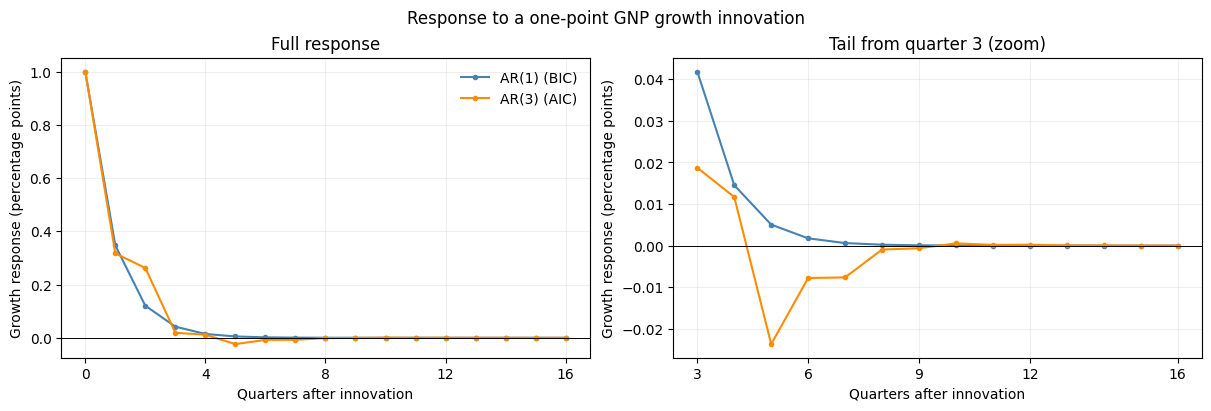

In [9]:
horizons = np.arange(17)

def impulse_response(fit, horizon=16):
    phi_parameters = fit.params.iloc[1:].to_numpy()
    values = np.zeros(horizon + 1)
    # A one-point innovation has an impact response of one.
    values[0] = 1
    for h in range(1, horizon + 1):
        # Propagate the innovation through all included AR lags.
        values[h] = sum(
            phi_parameters[j - 1] * values[h - j]
            for j in range(1, min(len(phi_parameters), h) + 1)
        )
    return values

responses = {label: impulse_response(fit) for label, fit in selected_models.items()}
response = responses["AR(1) (BIC)"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for (label, values), color in zip(responses.items(), ["steelblue", "darkorange"]):
    axes[0].plot(horizons, values, marker="o", markersize=3, color=color, label=label)
    # The second panel enlarges the small response after quarter two.
    axes[1].plot(horizons[3:], values[3:], marker="o", markersize=3, color=color, label=label)
for ax, title in zip(axes, ["Full response", "Tail from quarter 3 (zoom)"]):
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set(title=title, xlabel="Quarters after innovation", ylabel="Growth response (percentage points)")
    ax.grid(alpha=0.2)
axes[0].set_xticks([0, 4, 8, 12, 16])
axes[1].set_xticks([3, 6, 9, 12, 16])
axes[0].legend(frameon=False)
fig.suptitle("Response to a one-point GNP growth innovation")
plt.show()

## Optional extension: the oscillatory period implied by AR(3)

The dynamic eigenvalues solve $\lambda^3-\phi_1\lambda^2-\phi_2\lambda-\phi_3=0$.
For a stable complex pair $\lambda=re^{\pm i\theta}$,

$$P=\frac{2\pi}{|\theta|}\quad\text{quarters},\qquad
H_{1/2}=\frac{\log(0.5)}{\log(r)}\quad\text{quarters}.$$

$P$ is the period of the oscillatory mode; $H_{1/2}$ is the half-life of its
exponential envelope. The estimated pair implies **10.7 quarters (2.7 years)**,
but its envelope halves in about **one quarter**. Only about **0.043%** of its
initial envelope remains after a full period. AR(3) also contains a negative
real mode with slightly larger modulus: the complex pair is not the dominant mode.

This is a rapidly damped component of the growth model, not an estimate of the
average duration of observed business cycles. Such a duration needs dated
turning points and a definition of a complete cycle. These are point estimates
conditional on the model and selected order, without a period uncertainty interval.

In [10]:
ar3_result = selected_models["AR(3) (AIC)"]
# statsmodels reports roots of the lag polynomial; invert them for the dynamic eigenvalues.
dynamic_eigenvalues = 1 / np.asarray(ar3_result.roots, dtype=complex)
# Use the member with positive imaginary part to describe the conjugate pair once.
complex_eigenvalue = dynamic_eigenvalues[dynamic_eigenvalues.imag > 1e-8][0]
radius = float(abs(complex_eigenvalue))
angle = float(abs(np.angle(complex_eigenvalue)))
# Separate the oscillatory period from the decay of its amplitude envelope.
period_quarters = 2 * np.pi / angle
period_years = period_quarters / 4
envelope_half_life = np.log(0.5) / np.log(radius)
remaining_envelope_pct = 100 * radius ** period_quarters
oscillation_summary = pd.DataFrame({
    "Modulus": [radius], "Period (quarters)": [period_quarters],
    "Period (years)": [period_years],
    "Envelope half-life (quarters)": [envelope_half_life],
    "Envelope after one period (%)": [remaining_envelope_pct],
}, index=["AR(3) complex pair"])
display(oscillation_summary.round(3))

,Modulus,Period (quarters),Period (years),Envelope half-life (quarters),Envelope after one period (%)
AR(3) complex pair,0.485,10.714,2.679,0.959,0.043


## Next-quarter forecasting

From the origin **2019Q4**, forecast **2020Q1** using each fitted model:

$$\widehat g_{T+1|T}=\widehat c+\sum_{j=1}^{p}\widehat\phi_jg_{T+1-j}.$$

Compare with the observed 2020Q1 value, which has not entered order selection
or estimation. The approximate 95% prediction interval is for future growth,
conditional on the fitted model. It omits parameter and order uncertainty and
assumes the fitted innovation variance remains relevant. This is one historical
forecast per model using revised data, not a broad forecast-performance test.

In [11]:
# The forecast origin is 2019Q4; the 2020Q1 outcome was held out of estimation.
next_quarter = growth.index[-1] + 1
prediction = result.get_prediction(start=len(growth), end=len(growth))
interval = np.asarray(prediction.conf_int(alpha=0.05))[0]
forecast = float(np.asarray(prediction.predicted_mean)[0])
actual = float(all_growth.loc[next_quarter])
forecast_rows = []
for label, fit in selected_models.items():
    pred = fit.get_prediction(start=len(growth), end=len(growth))
    # These prediction bounds condition on the fitted coefficients and lag order.
    bounds = np.asarray(pred.conf_int(alpha=0.05))[0]
    point = float(np.asarray(pred.predicted_mean)[0])
    forecast_rows.append({
        "Model": label, "Quarter": str(next_quarter), "Forecast (%)": point,
        "95% lower": bounds[0], "95% upper": bounds[1], "Observed (%)": actual,
        "Error (actual - forecast)": actual - point,
    })
forecast_table = pd.DataFrame(forecast_rows).set_index("Model")
display(forecast_table.round(3))

,Quarter,Forecast (%),95% lower,95% upper,Observed (%),Error (actual - forecast)
Model,,,,,,
AR(1) (BIC),2020Q1,0.722,-0.982,2.427,-1.281,-2.003
AR(3) (AIC),2020Q1,0.773,-0.906,2.452,-1.281,-2.054


## Extending the sample through 2025

As a final sensitivity check, repeat the same lag selection on the complete,
contiguous sample through 2025Q4. Compare selected orders and the AR(1)
coefficient on each sample. The full-sample AR(1) is a comparison model even
when BIC selects AR(0).

In [12]:
# Apply the same maximum order and common hold-back within each sample.
comparison_rows = []
for label, y in [("Through 2019Q4", growth), ("Through 2025Q4", all_growth)]:
    sample_models, table, p = fit_candidates(y)
    # Keep AR(1) for comparison even when BIC selects an intercept-only model.
    comparison_rows.append({
        "Sample end": label, "n": int(sample_models[p].nobs),
        "BIC order": p, "AIC order": int(table["AIC"].idxmin()),
        "AR(1) coefficient": sample_models[1].params.iloc[1],
    })
sample_comparison = pd.DataFrame(comparison_rows).set_index("Sample end")
display(sample_comparison.round(4))

,n,BIC order,AIC order,AR(1) coefficient
Sample end,,,,
Through 2019Q4,283,1,3,0.3471
Through 2025Q4,307,0,2,0.1135


BIC switches from AR(1) to AR(0), while AIC selects AR(2) on the full sample.
The AR(1) estimate remains positive but falls from about 0.35 to 0.11.
The large 2020 contraction and rebound can strongly affect a constant-parameter
model. The samples also differ in length and in other observations after 2019,
so this comparison alone does not establish a structural break or its cause.
Changing from GDP to GNP does not guarantee an order greater than zero;
AR(0) remains a sample-specific selection outcome.